In [2]:
# Import Required Libraries
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point


In [3]:
# Load old retail centre boundaries
gpkg_path = '../data/old_retail_centres/Retail_Boundaries_UK.gpkg'
old_centres = gpd.read_file(gpkg_path)
old_centres = old_centres.to_crs('EPSG:4326')  # Ensure WGS84 for spatial join
old_centres.head()

# Load filtered Foursquare POI data
foursquare_path = '../data/input_files/uk_foursquare_datefields_admin_categories_retailfiltnew_geo.parquet'
foursquare = gpd.read_parquet(foursquare_path)
foursquare = foursquare.to_crs('EPSG:4326')  # Ensure WGS84 for spatial join

new_centres_10 =  gpd.read_parquet("../data/output_files/mergeafterfiltthresh_retailcen_foursquare_mrc_2_mri_1_mrn_10_mtf_6_splitthresh_1500_merge_y/4_finalcentres_las.parquet")
new_centres_15 = gpd.read_parquet("../data/output_files/mergeafterfiltthresh_retailcen_foursquare_mrc_2_mri_1_mrn_15_mtf_6_splitthresh_1500_merge_y/4_finalcentres_las.parquet")
# new_centres = gpd.read_parquet("../data/output_files/fsqup_retailcen_foursquare_mrc_2_mri_10_mrn_10_mtf_6_splitthresh_1500_merge_n/4_finalcentres_las.parquet")
# new_centres = gpd.read_parquet("../data/output_files/mergeafterfiltthresh_retailcen_foursquare_mrc_2_mri_10_mrn_10_mtf_6_splitthresh_1500_merge_y/4_finalcentres_las.parquet")


In [ ]:
import geopandas as gpd

# Ensure both GeoDataFrames use the same CRS (WGS84 for spatial join)
new_centres_10 = new_centres_10.to_crs('EPSG:4326')
new_centres_15 = new_centres_15.to_crs('EPSG:4326')

# Perform spatial join: find features in new_centres_10 that intersect with any in new_centres_15
joined = gpd.sjoin(new_centres_10, new_centres_15, how='left', predicate='intersects')

# Fix: .isnull should be called as a method with parentheses
new_centres_10_not_in_15 = joined[joined['index_right'].isnull()].copy()

# Drop the index_right column added by the spatial join
new_centres_10_not_in_15 = new_centres_10_not_in_15.drop(columns=['index_right'])
new_centres_10_not_in_15.to_parquet("../data/output_files/new_centres_10_not_in_15.parquet")




In [ ]:
#get centrs in old_centres that do not intersect with new_centres_10
joined_old = gpd.sjoin(old_centres, new_centres_10, how='left', predicate='intersects')
old_centres_not_in_new = joined_old[joined_old['index_right'].isnull()].copy()
# Drop the index_right column added by the spatial join
old_centres_not_in_new = old_centres_not_in_new.drop(columns=['index_right'])
old_centres_not_in_new.to_parquet("../data/output_files/old_centres_not_in_new_centres.parquet")

# Step 3: Spatial join to count POIs within each old centre boundary
poi_joined = gpd.sjoin(foursquare, old_centres_not_in_new, how='inner', predicate='within')

# Count POIs per old centre (assuming there's a unique ID column, e.g., 'index' or 'centre_id')
# Replace 'index' if your identifier column has a different name
foursquarepoi_counts = poi_joined.groupby(poi_joined.index_right).size().rename("foursquare_poi_count")

# Add the counts back to the old_centres_not_in_new GeoDataFrame
old_centres_not_in_new["foursquare_poi_count"] = old_centres_not_in_new.index.map(foursquare_poi_counts).fillna(0).astype(int)

# Save to parquet
old_centres_not_in_new.to_parquet("../data/output_files/old_centres_not_in_new_centres.parquet")

In [11]:
len(old_centres_not_in_new)

381

## Spatial Join: Count Foursquare POIs in Each Retail Centre
Perform a spatial join to count the number of Foursquare POIs within each retail centre polygon.

In [10]:
# Spatial join: count Foursquare POIs in each retail centre
joined = gpd.sjoin(foursquare, old_centres, how='left', predicate='within')
counts = joined.groupby('index_right').size().reset_index(name='foursquare_poi_count')
# Merge counts back to old_centres
table = old_centres.reset_index().merge(counts, left_on='index', right_on='index_right', how='left')
table['foursquare_poi_count'] = table['foursquare_poi_count'].fillna(0).astype(int)
table[['index', 'foursquare_poi_count'] + [col for col in old_centres.columns if col != 'geometry']].head()



,index,foursquare_poi_count,RC_ID,RC_Name,Classification,Country,Region_NM,H3_count,Retail_N,Area_km2
0,0,99,RC_EW_1004,Melton Road; Belgrave; Leicester (East Midland...,Local Centre,England,East Midlands,19.0,141.0,0.036693
1,1,203,RC_EW_101,Hessle Road; Dairycoates; City of Kingston upo...,District Centre,England,Yorkshire and The Humber,131.0,252.0,0.245969
2,2,220,RC_EW_1010,Belgrave Road; Belgrave; Leicester (East Midla...,District Centre,England,East Midlands,43.0,216.0,0.082949
3,3,78,RC_EW_1013,Beaumont Shopping Centre; Leicester (East Midl...,Large Retail Park,England,East Midlands,87.0,48.0,0.167440
4,4,1743,RC_EW_1014,Leicester; Leicester (East Midlands; England),Major Town Centre,England,East Midlands,268.0,1431.0,0.515804


Threshold: 5, Number of new centres: 26714
Number of new centres intersecting with old centres at threshold 5: 6524
Number of old centres not intersecting with new centres at threshold 5: 183
Threshold: 6, Number of new centres: 21731
Number of new centres intersecting with old centres at threshold 6: 6376
Number of old centres not intersecting with new centres at threshold 6: 210
Threshold: 7, Number of new centres: 18328
Number of new centres intersecting with old centres at threshold 7: 6245
Number of old centres not intersecting with new centres at threshold 7: 250
Threshold: 8, Number of new centres: 15837
Number of new centres intersecting with old centres at threshold 8: 6148
Number of old centres not intersecting with new centres at threshold 8: 273
Threshold: 9, Number of new centres: 13892
Number of new centres intersecting with old centres at threshold 9: 6033
Number of old centres not intersecting with new centres at threshold 9: 328
Threshold: 10, Number of new centres: 12

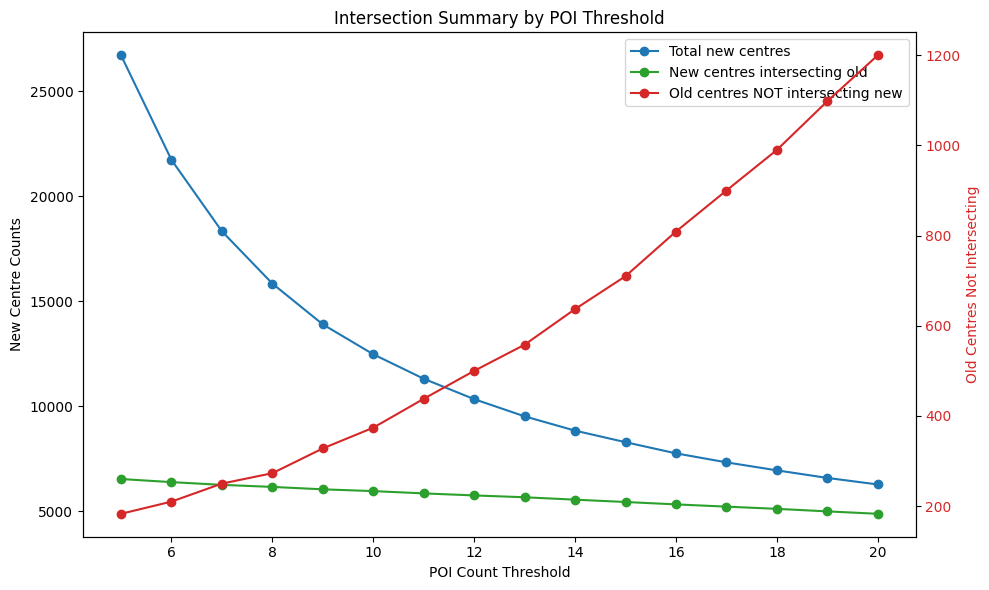

In [11]:
import matplotlib.pyplot as plt

# Ensure both GeoDataFrames share the same CRS
if table.crs != new_centres.crs:
    new_centres = new_centres.to_crs(table.crs)

thresholds = list(range(5, 21))

# Lists to store values for plotting
num_new_centres = []
num_new_centres_intersecting_old = []
num_old_centres_not_intersecting_new = []

for threshold in thresholds:
    new_centres_thresh = new_centres[new_centres['POI_count'] >= threshold].copy()

    n_new = len(new_centres_thresh)
    print(f"Threshold: {threshold}, Number of new centres: {n_new}")
    num_new_centres.append(n_new)

    # Check intersection: old centres intersecting any new ones
    table[f'intersects_new_{threshold}'] = table.geometry.apply(
        lambda geom: new_centres_thresh.intersects(geom).any()
    )

    # Check reverse: new centres intersecting any old ones
    new_centres_thresh[f'intersects_old_{threshold}'] = new_centres_thresh.geometry.apply(
        lambda geom: table.intersects(geom).any()
    )

    n_new_intersect = new_centres_thresh[f'intersects_old_{threshold}'].sum()
    n_old_not_intersect = len(table) - table[f'intersects_new_{threshold}'].sum()

    print(f"Number of new centres intersecting with old centres at threshold {threshold}: {n_new_intersect}")
    print(f"Number of old centres not intersecting with new centres at threshold {threshold}: {n_old_not_intersect}")

    num_new_centres_intersecting_old.append(n_new_intersect)
    num_old_centres_not_intersecting_new.append(n_old_not_intersect)

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot primary y-axis
ax1.plot(thresholds, num_new_centres, label="Total new centres", color="tab:blue", marker="o")
ax1.plot(thresholds, num_new_centres_intersecting_old, label="New centres intersecting old", color="tab:green", marker="o")
ax1.set_xlabel("POI Count Threshold")
ax1.set_ylabel("New Centre Counts", color="black")
ax1.tick_params(axis="y", labelcolor="black")

# Create secondary y-axis
ax2 = ax1.twinx()
ax2.plot(thresholds, num_old_centres_not_intersecting_new, label="Old centres NOT intersecting new", color="tab:red", marker="o")
ax2.set_ylabel("Old Centres Not Intersecting", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

# Combine legends from both axes
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper right")

plt.title("Intersection Summary by POI Threshold")
plt.tight_layout()
plt.show()


# Make Alex Plot

In [19]:
new_centres =  gpd.read_parquet("../data/output_files/newfilpo_retailcen_foursquare_mrc_2_mri_10_mrn_10_mtf_6_splitthresh_1500_merge_n/4_finalcentres_las.parquet")

if table.crs != new_centres.crs:
    new_centres = new_centres.to_crs(table.crs)

# Check intersection and add column
table['intersects_new'] = table.geometry.apply(
    lambda geom: new_centres.intersects(geom).any()
)

# Show result
display_cols = table.columns.tolist()
if 'intersects_new' in display_cols:
    display_cols.remove('geometry')
table[display_cols + ['geometry']].head()

,index,RC_ID,RC_Name,Classification,Country,Region_NM,H3_count,Retail_N,Area_km2,index_right,...,intersects_new_13,intersects_new_14,intersects_new_15,intersects_new_16,intersects_new_17,intersects_new_18,intersects_new_19,intersects_new_20,intersects_new,geometry
0,0,RC_EW_1004,Melton Road; Belgrave; Leicester (East Midland...,Local Centre,England,East Midlands,19.0,141.0,0.036693,0.0,...,True,True,True,True,True,True,True,True,True,"POLYGON ((-1.11937 52.65398, -1.1193 52.65373,..."
1,1,RC_EW_101,Hessle Road; Dairycoates; City of Kingston upo...,District Centre,England,Yorkshire and The Humber,131.0,252.0,0.245969,1.0,...,True,True,True,True,True,True,True,True,True,"POLYGON ((-0.37734 53.73328, -0.37766 53.73315..."
2,2,RC_EW_1010,Belgrave Road; Belgrave; Leicester (East Midla...,District Centre,England,East Midlands,43.0,216.0,0.082949,2.0,...,True,True,True,True,True,True,True,True,True,"POLYGON ((-1.12546 52.64615, -1.12539 52.64591..."
3,3,RC_EW_1013,Beaumont Shopping Centre; Leicester (East Midl...,Large Retail Park,England,East Midlands,87.0,48.0,0.167440,3.0,...,True,True,True,True,True,True,True,True,True,"POLYGON ((-1.16494 52.66344, -1.16487 52.6632,..."
4,4,RC_EW_1014,Leicester; Leicester (East Midlands; England),Major Town Centre,England,East Midlands,268.0,1431.0,0.515804,4.0,...,True,True,True,True,True,True,True,True,True,"POLYGON ((-1.13354 52.63183, -1.13347 52.63158..."


In [20]:
#also just save as a pandas dataframe parquet file
table.to_parquet('../data/forarcgis/old_centres_with_foursquare_and_new_intersection.parquet', index=False)
#sort by foursquare_poi_count and save as csv and parquet
table_sorted = table.sort_values(by='foursquare_poi_count', ascending=False)
table_sorted.to_csv('../data/forarcgis/old_centres_with_foursquare_and_new_intersection_sorted.csv', index=False)
table_sorted.to_parquet('../data/forarcgis/old_centres_with_foursquare_and_new_intersection_sorted.parquet', index=False)

In [22]:
#number of centrs with zero retail N
zero_retail_centres = table[table['Retail_N'] == 0].shape[0]
print(f'Number of centres with zero Retail_N: {zero_retail_centres}')

#number less than 10 retail N
less_than_ten_retail_centres = table[table['Retail_N'] < 10].shape[0]
print(f'Number of centres with Retail_N less than 10: {less_than_ten_retail_centres}')

Number of centres with zero Retail_N: 510
Number of centres with Retail_N less than 10: 724


## Display Results
Display the resulting table with the count of Foursquare POIs per retail centre. You can also view a summary or sample of the results.

In [23]:
#how many centres have less than 10 foursquare POIs and don't intersect with new centres
#centres which don't intersect with new centres
centres_which_dont_intersect = table[~table['intersects_new']]
centres_which_dont_intersect_count = len(centres_which_dont_intersect)
print(f"Number of centres that do not intersect with new centres: {centres_which_dont_intersect_count}")
centres_with_few_pois = table[table['foursquare_poi_count'] < 10]
print(f"Number of centres with less than 10 Foursquare POIs: {len(centres_with_few_pois)}")
#and how many of those don't intersect with new centres
centres_with_few_pois_no_intersection = centres_with_few_pois[~centres_with_few_pois['intersects_new']]
print(f"Number of centres with less than 10 Foursquare POIs and no intersection with new centres: {len(centres_with_few_pois_no_intersection)}")

Number of centres that do not intersect with new centres: 374
Number of centres with less than 10 Foursquare POIs: 609
Number of centres with less than 10 Foursquare POIs and no intersection with new centres: 315


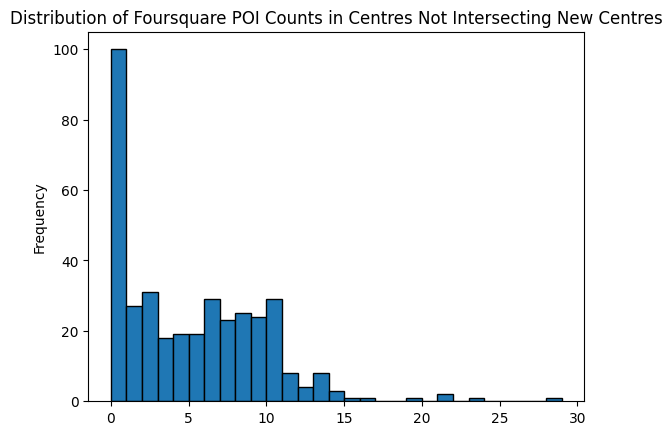

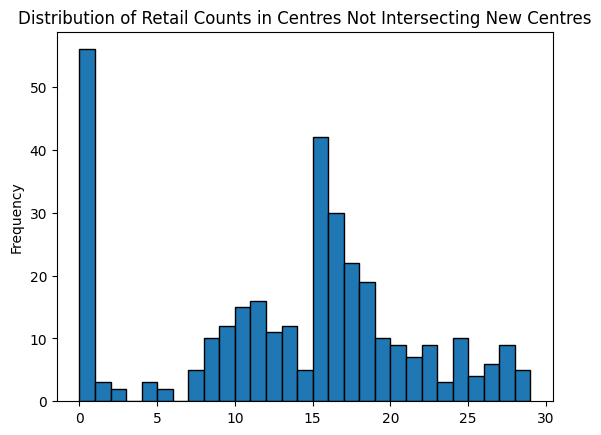

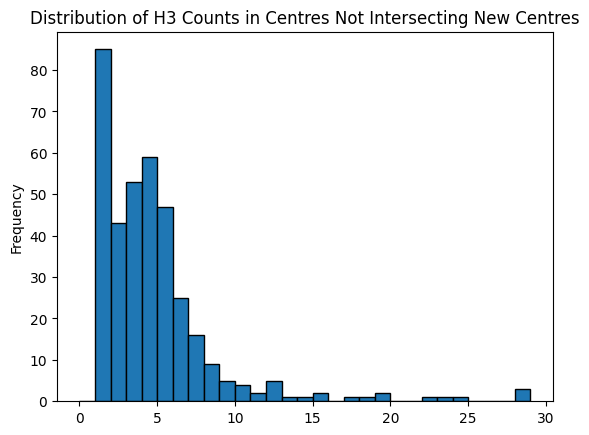

In [30]:
import matplotlib.pyplot as plt
bins = range(0, 30, 1)
centres_which_dont_intersect["foursquare_poi_count"].plot(kind="hist", bins=bins, edgecolor='black')
plt.title("Distribution of Foursquare POI Counts in Centres Not Intersecting New Centres")
plt.show()

centres_which_dont_intersect["Retail_N"].plot(kind="hist", bins=bins, edgecolor='black')
plt.title("Distribution of Retail Counts in Centres Not Intersecting New Centres")
plt.show()

centres_which_dont_intersect["H3_count"].plot(kind='hist', bins=bins, edgecolor='black')
plt.title("Distribution of H3 Counts in Centres Not Intersecting New Centres")
plt.show()


In [25]:
#wheres the 140 one
centres_which_dont_intersect[centres_which_dont_intersect["H3_count"]>90]

,index,RC_ID,RC_Name,Classification,Country,Region_NM,H3_count,Retail_N,Area_km2,geometry,...,intersects_new_12,intersects_new_13,intersects_new_14,intersects_new_15,intersects_new_16,intersects_new_17,intersects_new_18,intersects_new_19,intersects_new_20,intersects_new
1269,1269,RC_EW_102,St. Andrews Quay Retail Park; City of Kingston...,Small Retail Park,England,Yorkshire and The Humber,153.0,22.0,0.287150,"POLYGON ((-0.38167 53.72484, -0.38161 53.72459...",...,False,False,False,False,False,False,False,False,False,False
3114,3114,RC_EW_2683,Newmarket Road; Fen Ditton; South Cambridgeshi...,Small Local Centre,England,East of England,109.0,0.0,0.207686,"POLYGON ((0.17777 52.2114, 0.17814 52.21129, 0...",...,False,False,False,False,False,False,False,False,False,False
4016,4016,RC_EW_3499,M4; Leigh Delamere; Wiltshire (South West; Eng...,Small Local Centre,England,South West,103.0,0.0,0.203934,"POLYGON ((-2.16059 51.5086, -2.16052 51.50835,...",...,False,False,False,False,False,False,False,False,False,False


In [26]:
#save as a parquet
centres_which_dont_intersect.to_parquet("centres_which_dont_intersect.parquet")

Text(0.5, 1.0, 'Old Retail Centres which do not intersect with new centres')

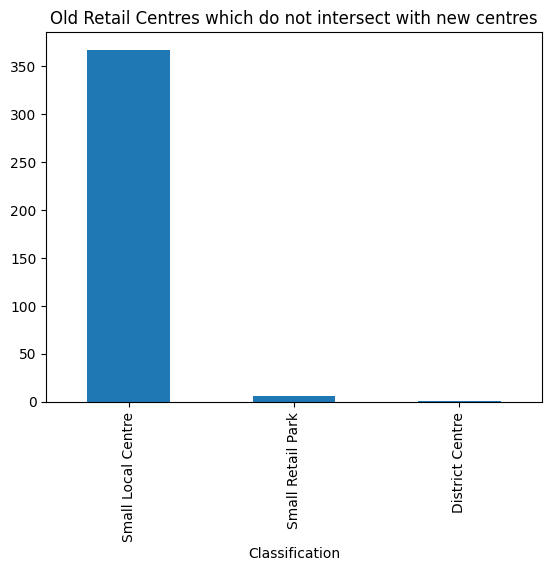

In [27]:
#plot bar of "Classification" of these centres
import matplotlib.pyplot as plt
centres_which_dont_intersect['Classification'].value_counts().plot(kind='bar')
plt.title('Old Retail Centres which do not intersect with new centres')

In [28]:
# Display summary and sample of results
print('Summary statistics:')
print(table['foursquare_poi_count'].describe())
table[['index', 'foursquare_poi_count'] + [col for col in old_centres.columns if col != 'geometry']].head(10)

Summary statistics:
count     6423.000000
mean        88.491982
std        269.707595
min          0.000000
25%         17.000000
50%         31.000000
75%         77.000000
max      16075.000000
Name: foursquare_poi_count, dtype: float64


,index,foursquare_poi_count,RC_ID,RC_Name,Classification,Country,Region_NM,H3_count,Retail_N,Area_km2
0,0,99,RC_EW_1004,Melton Road; Belgrave; Leicester (East Midland...,Local Centre,England,East Midlands,19.0,141.0,0.036693
1,1,203,RC_EW_101,Hessle Road; Dairycoates; City of Kingston upo...,District Centre,England,Yorkshire and The Humber,131.0,252.0,0.245969
2,2,220,RC_EW_1010,Belgrave Road; Belgrave; Leicester (East Midla...,District Centre,England,East Midlands,43.0,216.0,0.082949
3,3,78,RC_EW_1013,Beaumont Shopping Centre; Leicester (East Midl...,Large Retail Park,England,East Midlands,87.0,48.0,0.167440
4,4,1743,RC_EW_1014,Leicester; Leicester (East Midlands; England),Major Town Centre,England,East Midlands,268.0,1431.0,0.515804
5,5,2307,RC_EW_1023,Nottingham; Nottingham (East Midlands; England),Regional Centre,England,East Midlands,372.0,1843.0,0.712908
6,6,180,RC_EW_1032,West Bridgford; Rushcliffe (East Midlands; Eng...,Town Centre,England,East Midlands,42.0,140.0,0.080642
7,7,165,RC_EW_1035,Radford Road; Hyson Green; Nottingham (East Mi...,District Centre,England,East Midlands,82.0,206.0,0.157314
8,8,181,RC_EW_1036,Alfreton Road; Radford; Nottingham (East Midla...,Local Centre,England,East Midlands,47.0,164.0,0.090185
9,9,51,RC_EW_1039,Castle Marina Retail Park; Nottingham (East Mi...,Large Retail Park,England,East Midlands,147.0,17.0,0.281820


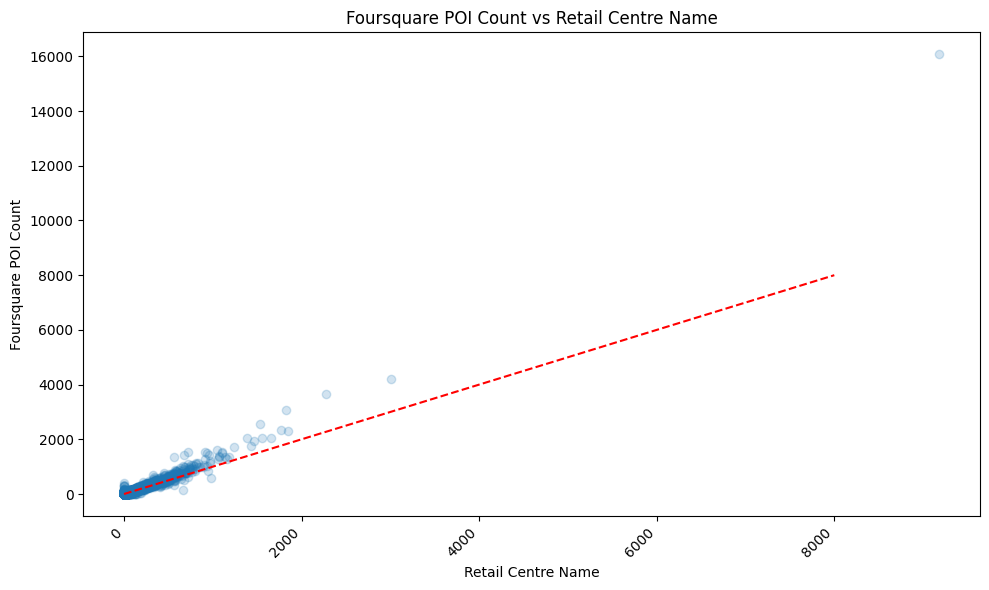

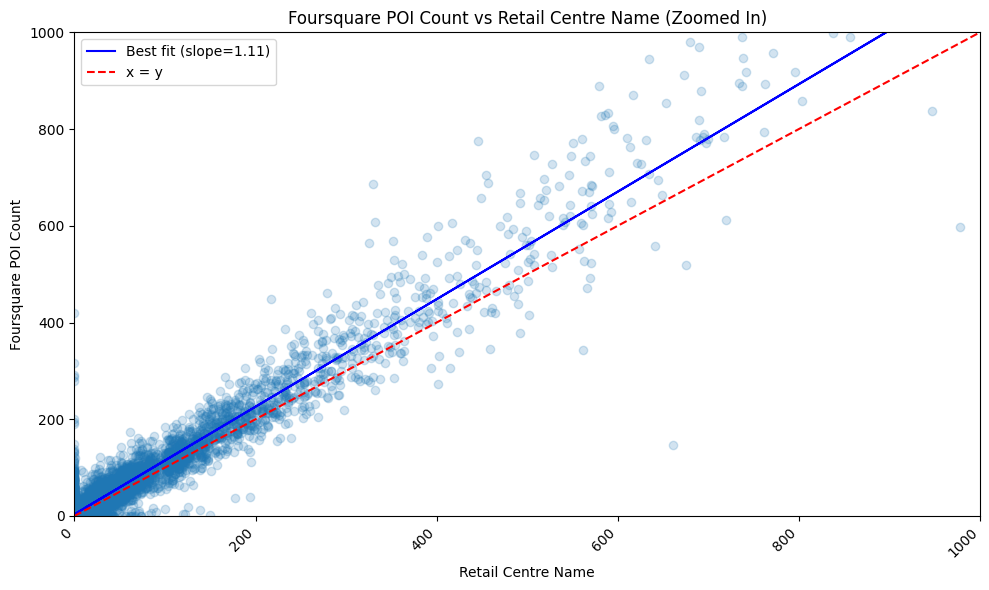

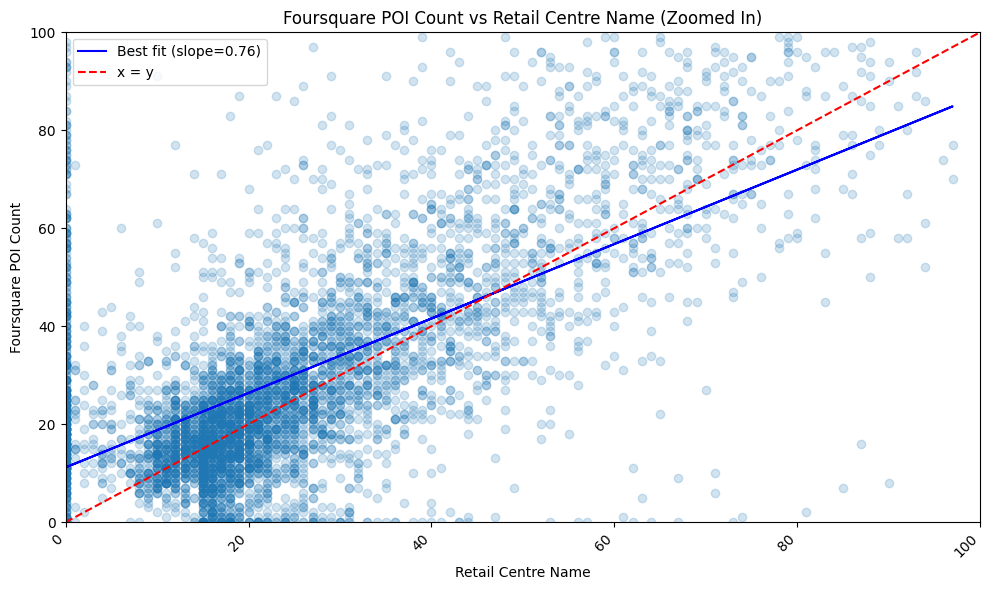

In [29]:
import matplotlib.pyplot as plt
import numpy as np

x = table['Retail_N']
y = table['foursquare_poi_count']

# Full plot (no line of best fit)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, alpha=0.2)
plt.plot([0, 8000], [0, 8000], color='red', linestyle='--', label='x = y')
plt.title('Foursquare POI Count vs Retail Centre Name')
plt.xlabel('Retail Centre Name')
plt.ylabel('Foursquare POI Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Zoomed in <1000
mask_1000 = (x < 1000) & (y < 1000)
x_1000 = x[mask_1000]
y_1000 = y[mask_1000]
slope_1000, intercept_1000 = np.polyfit(x_1000, y_1000, 1)
line_1000 = slope_1000 * x_1000 + intercept_1000

plt.figure(figsize=(10, 6))
plt.scatter(x_1000, y_1000, alpha=0.2)
plt.plot(x_1000, line_1000, color='blue', label=f'Best fit (slope={slope_1000:.2f})')
plt.plot([0, 1000], [0, 1000], color='red', linestyle='--', label='x = y')
plt.title('Foursquare POI Count vs Retail Centre Name (Zoomed In)')
plt.xlabel('Retail Centre Name')
plt.ylabel('Foursquare POI Count')
plt.xlim(0, 1000)
plt.ylim(0, 1000)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# Zoomed in <100
mask_100 = (x < 100) & (y < 100)
x_100 = x[mask_100]
y_100 = y[mask_100]
slope_100, intercept_100 = np.polyfit(x_100, y_100, 1)
line_100 = slope_100 * x_100 + intercept_100

plt.figure(figsize=(10, 6))
plt.scatter(x_100, y_100, alpha=0.2)
plt.plot(x_100, line_100, color='blue', label=f'Best fit (slope={slope_100:.2f})')
plt.plot([0, 100], [0, 100], color='red', linestyle='--', label='x = y')
plt.title('Foursquare POI Count vs Retail Centre Name (Zoomed In)')
plt.xlabel('Retail Centre Name')
plt.ylabel('Foursquare POI Count')
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()


## Intersecting Old and New Retail Centres

In this section, we load the new retail centres from the provided zipped GeoPackage and check for intersections with the old centres. A new column will be added to the old centres indicating whether each one intersects with any of the new centres.